# Homework 4: Denoising Diffusion Probabilistic Model (DDPM)

## Task 1: Theory (5 pts)

### Problem 1: Conditioned reverse distribution for NCSN (2 pts)

In NCSN, the marginal distribution at noise level $t$ is given by
$$
\mathbf{x}_t = \mathbf{x}_0 + \sigma_t \boldsymbol{\epsilon},
\qquad
\boldsymbol{\epsilon} \sim \mathcal{N}(0,\mathbf{I}),
$$
or equivalently,
$$
q(\mathbf{x}_t | \mathbf{x}_0)
=
\mathcal{N}(\mathbf{x}_0,\sigma_t^2 \mathbf{I}),
\qquad
0 = \sigma_0 < \sigma_1 < \sigma_2 < \dots < \sigma_T.
$$

Interestingly, the same marginals can be realized through a forward noising process that forms a Gaussian Markov chain with transitions
$$
q(\mathbf{x}_t | \mathbf{x}_{t-1})
=
\mathcal{N}\!\left(
\mathbf{x}_{t-1},
(\sigma_t^2-\sigma_{t-1}^2)\mathbf{I}
\right).
$$
This construction guarantees that the induced marginal distribution of $\mathbf{x}_t$ conditioned on $\mathbf{x}_0$ is exactly $q(\mathbf{x}_t | \mathbf{x}_0) = \mathcal{N}(\mathbf{x}_0,\sigma_t^2 \mathbf{I})$.

By viewing the NCSN noising process as a forward Gaussian Markov chain, the posterior distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$ becomes well-defined. Your task is to derive this posterior distribution for $t=2,\ldots,T$.

**Note:** for this problem, do **not** interpret different noise levels as if they were sampled independently from $\mathbf{x}_0$. Instead, assume that the noisy samples are coupled through the forward Gaussian Markov chain above. This coupling is what allows us to define the reverse conditional distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$.

**Hint:** the resulting posterior must be Gaussian, and its mean should be expressed as a convex combination of $\mathbf{x}_t$ and $\mathbf{x}_0$.

```
your solution
```

### Problem 2. Gaussian diffusion (2 pts)

**(a) Why these DDPM coefficients? (0.5 pts)** [Lecture 7](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/lectures/lecture7/Lecture7.pdf) showed that for a constant $0<\beta<1$, the step
$$
\mathbf x_t=\sqrt{1-\beta}\,\mathbf x_{t-1}+\sqrt{\beta}\,\boldsymbol\epsilon_t
$$
converges under iteration to $\mathcal N(\mathbf 0,\mathbf I)$ from any fixed starting point $\mathbf x_0$.

Prove the converse within the same class of steps. Suppose $\mathbf x_t=a\mathbf x_{t-1}+b\boldsymbol\epsilon_t$, with constant $0<a<1$, $b>0$ and independent $\boldsymbol\epsilon_t\sim\mathcal N(\mathbf 0,\mathbf I)$. If the limiting law is standard Gaussian for every fixed $\mathbf x_0$, show that there must be a $\beta\in(0,1)$ for which $a=\sqrt{1-\beta}$ and $b=\sqrt\beta$.

**(b) From noise levels to transitions (1.5 pts)** Suppose we are given the signal coefficients $c_t$ and noise variances $\sigma_t^2$ for each time $t$, so the desired conditional law from every starting point is
$$
q(\mathbf x_t\mid\mathbf x_0)=\mathcal N(c_t\mathbf x_0,\sigma_t^2\mathbf I).
$$
Here $c_0=1$, $\sigma_0=0$, and $c_t,\sigma_t>0$ for $1\le t\le T$. We seek a Markov chain in which each step rescales the previous state by a scalar and adds independent, centered, isotropic Gaussian noise.

For $0\le s<t\le T$, find the two parameters of its transition
$$
q(\mathbf x_t\mid\mathbf x_s)
=\mathcal N\!\left(c_{t\mid s}\mathbf x_s,\ \sigma_{t\mid s}^{2}\mathbf I\right).
$$
Express the **signal multiplier** $c_{t\mid s}$ and the **noise variance per coordinate** $\sigma_{t\mid s}^2$ in terms of $c_s,c_t,\sigma_s^2,\sigma_t^2$. Then give a necessary and sufficient condition on the schedule for the chain to exist and justify both directions. A step may have zero noise variance.

```
your solution
```

### Problem 3. Estimating the change in log density along a flow (1 pt)

**(a) From KFP to the exact rate (0.5 pts).** Let $p_t(\mathbf x)>0$ be a smooth density. Recall the Kolmogorov–Fokker–Planck equation
$$
\partial_t p_t=-\operatorname{div}(\mathbf f p_t)+\tfrac12g(t)^2\Delta p_t .
$$
Consider a continuous-time normalizing flow with velocity $\mathbf v$, so $g=0$, $\mathbf f=\mathbf v$ and $\dot{\mathbf x}(t)=\mathbf v(\mathbf x(t),t)$. Use KFP to express the total derivative $\frac{d}{dt}\log p_t(\mathbf x(t))$ in terms of the velocity Jacobian $\mathbf J=\partial\mathbf v/\partial\mathbf x$ at $(\mathbf x(t),t)$.

**(b) One random estimate (0.5 pts).** At this fixed point and time, draw a vector $\boldsymbol\epsilon$ with independent coordinates, each equally likely to be $+1$ or $-1$. Show that $-\boldsymbol\epsilon^\top\mathbf J\boldsymbol\epsilon$ is an unbiased estimate of the rate in (a). For the two-dimensional velocity field $\mathbf v(\mathbf x)=(x_2,0)^\top$, find the exact rate and the possible values of a single estimate.

```
your solution
```

In [ ]:
COMMIT_HASH = "6d3b720afc1f41e7009b7b67450e8ac58327964d"
!if [ -d dgm_utils ]; then rm -Rf dgm_utils; fi
!git clone https://github.com/r-isachenko/dgm_utils.git
%cd dgm_utils
!git checkout {COMMIT_HASH}
!pip install ./
%cd ./..
!rm -Rf dgm_utils

In [2]:
from dgm_utils import train_model
from dgm_utils import show_samples, visualize_images, load_dataset, visualize_2d_data, visualize_2d_samples
from dgm_utils import BaseModel, LabeledDataset

In [ ]:
import numpy as np
from typing import Tuple, List, Optional
import math
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
from tqdm.auto import tqdm
from torchmetrics.image.fid import FrechetInceptionDistance as FID

if torch.cuda.is_available():
    DEVICE = "cuda"
    print('GPU found :)')
else:
    DEVICE = "cpu"
    print('GPU not found :(')

## Task 2: DDPM on CIFAR10 with classifier-free guidance (6 pts)

In this task, we will train a DDPM on CIFAR10 and use classifier-free guidance to generate images of a chosen class.

In [ ]:
train_data, train_labels, test_data, test_labels = load_dataset("cifar10", flatten=False, binarize=False, with_targets=True)
visualize_images(train_data, "CIFAR10 samples")

Below you see the utility function, which broadcasts tensors. Look carefully at this code, we will use it in the majority of methods.

In [5]:
def extract_into_tensor(
    arr: torch.Tensor, 
    indices: torch.Tensor, 
    broadcast_shape: torch.Size
) -> torch.Tensor:
    assert len(arr.shape) == 1
    res = arr.to(device=indices.device)[indices].float()
    while len(res.shape) < len(broadcast_shape):
        res = res[..., None]


    return res.expand(broadcast_shape)

### Forward Diffusion

Let start with forward diffusion.

**Forward process** is defined as a posterior distribution $q(\mathbf{x}_{1:T}|\mathbf{x}_0)$.

It is a Markov chain, which consequently adds Gaussian noise to a given object $\mathbf{x}_0$.

At every step of this process the Gaussian noise is added with different magnitude, which is determined with a schedule of variances $\{\beta_1, ... \beta_T\}$.
If this schedule is chosen properly and T goes to infinity (or is large enough), we will converge to pure noise $\mathcal{N}(0, I)$.

Markov chain is defined by:
$$
 q(\mathbf{x}_t | \mathbf{x}_{t - 1}) = \mathcal{N}(\mathbf{x}_t | \sqrt{1 - \beta_t}\mathbf{x}_{t - 1}, \beta_t \mathbf{I}), \quad q(\mathbf{x}_{1:T}|\mathbf{x}_0) = \prod_{t = 1}^T q(\mathbf{x}_t | \mathbf{x}_{t - 1})
$$

In order to get $\mathbf{x}_t$ we have to compute $\mathbf{x}_1, ..., \mathbf{x}_{t - 1}$ iteratively.

Hopefully, due to the properties of the Gaussian distribution we can do it more efficiently.

Let's denote
$\alpha_t = 1- \beta_t$ и $\bar{\alpha}_t= \prod_{s = 1}^t\alpha_s$.
Then
$$
q(\mathbf{x}_t | \mathbf{x}_0) = \mathcal{N}(\mathbf{x}_t|\sqrt{\bar{\alpha}_t} \mathbf{x}_0, (1-\bar{\alpha}_t) \mathbf{I}).
\tag{1}
$$

Here we could get very useful expression
$$
    \mathbf{x}_t = \sqrt{\bar{\alpha}_t} \mathbf{x}_0 + \sqrt{1-\bar{\alpha}_t} \cdot \boldsymbol{\epsilon}. \tag{2}
$$

Now we will create base class for diffusion (we will use it as a python base class for forward and backward diffusions).

In [ ]:
class BaseDiffusion:
    def __init__(self, num_timesteps: int):
        self.num_timesteps = num_timesteps
        self.betas = self._get_beta_schedule(num_timesteps)
        self.alphas = 1 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=-1)
    
    @staticmethod
    def _get_beta_schedule(num_diffusion_timesteps: int, s: float = 0.008):
        def f(t, T):
            return (np.cos((t / T + s) / (1 + s) * np.pi / 2)) ** 2

        alphas = []
        f0 = f(0, num_diffusion_timesteps)

        for t in range(num_diffusion_timesteps + 1):
            alphas.append(f(t, num_diffusion_timesteps) / f0)

        betas = []

        for t in range(1, num_diffusion_timesteps + 1):
            betas.append(min(1 - alphas[t] / alphas[t - 1], 0.999))

        return torch.from_numpy(np.array(betas)).double()


basediff = BaseDiffusion(num_timesteps=20)

plt.plot(basediff.betas.numpy())
plt.title('Beta schedule')
plt.grid()
plt.show()

We are ready to define forward diffusion process. It has 2 methods:
- to get mean and variance of the distribution $q(\mathbf{x}_t | \mathbf{x}_0)$,
- to get samples from this distribution.

In [ ]:
class ForwardDiffusion(BaseDiffusion):
    def get_mean_variance(self, x0: torch.Tensor, t: torch.Tensor):
        # ====
        # your code
        # calculate mean and variance of the distribution q(x_t | x_0) (use equation (1))
        # use extract_into_tensor() function to get tensors of the same shape as x0
        
        # ====
        return mean, variance

    def get_samples(
        self, 
        x0: torch.Tensor, 
        t: torch.Tensor, 
        noise: Optional[torch.Tensor] = None
    ):
        if noise is None:
            noise = torch.randn_like(x0)
        # ====
        # your code
        # sample from the distribution q(x_t | x_0) (use equation (2))
        
        # ====
        return samples


def test_forward_diffusion():
    fdiff = ForwardDiffusion(num_timesteps=100)
    SHAPE = [2, 20]
    x0 = torch.ones(SHAPE)
    t = torch.ones((2,)).long() * 5
    mean, variance = fdiff.get_mean_variance(x0=x0, t=t)
    assert list(mean.shape) == SHAPE
    assert list(variance.shape) == SHAPE
    assert np.allclose(mean.numpy(), np.ones(SHAPE) * 0.9944681)
    assert np.allclose(variance.numpy(), np.ones(SHAPE) * 0.01103322)

    xt = fdiff.get_samples(x0=x0, t=t)
    assert list(xt.shape) == SHAPE

    noise = torch.ones(SHAPE)
    xt = fdiff.get_samples(x0=x0, t=t, noise=noise)
    assert np.allclose(xt.numpy(), np.ones(SHAPE) * 1.0995072)


test_forward_diffusion()

Let's take a look at the forward process for the CIFAR10 images.

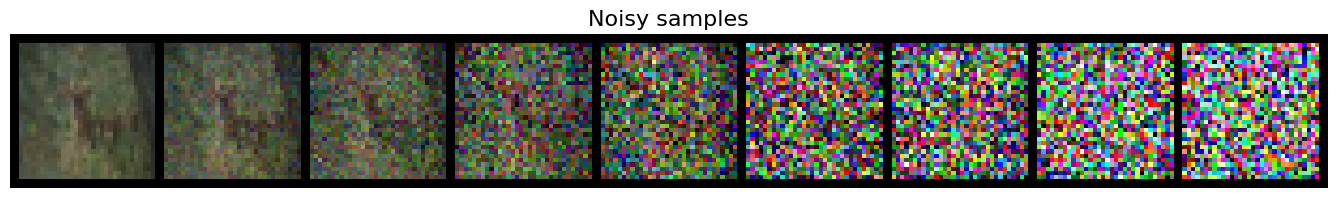

In [8]:
num_timesteps = 1000

fdiff = ForwardDiffusion(num_timesteps=num_timesteps)

timestamps=[0, 50, 100, 200, 300, 500, 600, 800, 999]

plot_n_steps = len(timestamps)
samples = []
x0 = train_data[10:11]
x0 = 2 * x0 - 1
for i, t in enumerate(timestamps):
    x = fdiff.get_samples(x0=torch.from_numpy(x0), t=torch.ones((x0.shape[0], 1)).long() * t)
    samples.append(x.cpu().numpy())

samples = np.concatenate(samples)
samples = (0.5 * samples + 0.5).clip(0, 1)
show_samples(samples, title="Noisy samples", nrow=len(timestamps), figsize=(20, 2))

### Reverse Diffusion

**Reverse process** consequently denoises pure Gaussian noise $\mathcal{N}(0, \mathbf{I})$ until we do not get the object from the original distribution $\pi(\mathbf{x})$.

It is a probability model with latent variables
$p(\mathbf{x}_0 | \boldsymbol{\theta}) := \int p(\mathbf{x}_{0:T} | \boldsymbol{\theta}) d\mathbf{x}_{1:T}$,
where
- latents $\mathbf{z} = \{\mathbf{x}_1, ..., \mathbf{x}_T\}$ correspond to noised objects
- $\mathbf{x}_0$ is an object from the original distribution $\pi(\mathbf{x})$.

Joint distribution $p(\mathbf{x}_{0:T} | \boldsymbol{\theta})$ is called reverse diffusion process, which is essentially a Markov chain of Gaussian distributions $p(\mathbf{x}_t|\mathbf{x}_t, \boldsymbol{\theta})$:
$$
p(\mathbf{x}_{0:T}) = p(\mathbf{x}_T) \prod_{t = 1}^T p(\mathbf{x}_{t-1}|\mathbf{x}_t, \boldsymbol{\theta}), \quad p(\mathbf{x}_{T} | \boldsymbol{\theta})=\mathcal{N}(0, \mathbf{I})
$$
$$
  p(\mathbf{x}_{t - 1}|\mathbf{x}_t | \boldsymbol{\theta}) = \mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\theta}, t}(\mathbf{x}_t), \boldsymbol{\sigma}^2_{\boldsymbol{\theta}, t}(\mathbf{x}_t)). \tag{3}
$$

In [Lecture 7](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/lectures/lecture7/Lecture7.pdf) we have derived ELBO for this model:

$$
    \mathcal{L}(q, \boldsymbol{\theta}) =  \mathbf{E}_{q} \Bigl[\log p(\mathbf{x}_0 | \mathbf{x}_1, \boldsymbol{\theta}) - KL\bigl(q(\mathbf{x}_T | \mathbf{x}_0) || p(\mathbf{x}_T)\bigr)
    - \sum_{t=2}^T \underbrace{KL \bigl(q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) || p(\mathbf{x}_{t - 1} | \mathbf{x}_t, \boldsymbol{\theta} )\bigr)}_{\mathcal{L}_t} \Bigr].
$$

Here we use the following distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) = \mathcal{N}( \boldsymbol{\mu}(\mathbf{x}_t, \mathbf{x}_0), \tilde{\beta}_t \mathbf{I}) $, where
$$
\boldsymbol{\mu}(\mathbf{x}_t, \mathbf{x}_0) = \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t} \mathbf{x}_0
\tag{4}
$$
$$
\tilde{\beta}_t = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \cdot \beta_t
\tag{5}
$$

(These scary formulas are not difficult to derive, follow the link to find details in [DDPM paper](https://arxiv.org/abs/2006.11239)).

Now our goal is to define parameters $\boldsymbol{\mu}_{\boldsymbol{\theta}, t}(\mathbf{x}_t), \boldsymbol{\sigma}^2_{\boldsymbol{\theta}, t}(\mathbf{x}_t)$ of reverse diffusion.

#### Variance
Our first assumption is to set the variance $\boldsymbol{\sigma}^2_{\boldsymbol{\theta}, t}(\mathbf{x}_t) = \tilde{\beta}_t$. This is very native assumption

#### Mean
Here we will use the expression (2) to get $\mathbf{x}_0$ from $\mathbf{x}_t$:
$$
    \mathbf{x}_0 = \frac{\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_{t}} \cdot \boldsymbol{\epsilon}}{\sqrt{\bar{\alpha}_{t}}}.
    \tag{6}
$$

If we put this expression to the formula (4) we will get:
$$
    \boldsymbol{\mu}(\mathbf{x}_t, \mathbf{x}_0) = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \cdot \boldsymbol{\epsilon} \right).
$$

So the idea here to parametrize the model mean in the same functional form:
$$
    \boldsymbol{\mu}_{\boldsymbol{\theta}, t}(\mathbf{x}_t) = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \cdot \boldsymbol{\epsilon}_{\boldsymbol{\theta}, t}(\mathbf{x}_t) \right).
$$

**Note:** our model will predict the noise which was applied to $\mathbf{x}_0$ to get $\mathbf{x}_t$.

The standard DDPM sampler moves from $t$ to $t-1$. To sample on a coarser grid, we use the same noise prediction at $t$ to take a reverse step directly to an earlier timestep $s$. In Theory Problem 2(b), we found the forward transition $q(\mathbf{x}_t\mid\mathbf{x}_s)$. Combining it with $q(\mathbf{x}_s\mid\mathbf{x}_0)$ via Bayes’ rule gives the posterior below. During sampling, we use the estimate $\hat{\mathbf{x}}_0$ obtained from the predicted noise using (6).
$$
    q(\mathbf{x}_s | \mathbf{x}_t, \mathbf{x}_0)
    =
    \mathcal{N}\bigl(\boldsymbol{\mu}_{t \to s}(\mathbf{x}_t, \mathbf{x}_0), \tilde{\beta}_{t \to s}\mathbf{I}\bigr),
$$
where
$$
    \boldsymbol{\mu}_{t \to s}(\mathbf{x}_t, \mathbf{x}_0)
    =
    \sqrt{\frac{\bar{\alpha}_t}{\bar{\alpha}_s}}
    \frac{1-\bar{\alpha}_s}{1-\bar{\alpha}_t}\mathbf{x}_t
    +
    \frac{\bar{\alpha}_s-\bar{\alpha}_t}{\sqrt{\bar{\alpha}_s}(1-\bar{\alpha}_t)}\mathbf{x}_0
$$
and
$$
    \tilde{\beta}_{t \to s}
    =
    \frac{1-\bar{\alpha}_s}{1-\bar{\alpha}_t}
    \left(1-\frac{\bar{\alpha}_t}{\bar{\alpha}_s}\right).
$$

Setting $s=t-1$ recovers the usual DDPM step. In the code, `s=-1` denotes the final transition to the clean image.


In [ ]:
class ReverseDiffusion(BaseDiffusion):
    def __init__(self, *args, clip_range: Optional[Tuple[float, float]] = None, **kwargs):
        super().__init__(*args, **kwargs)
        self.clip_range = clip_range

    def get_x0(self, xt: torch.Tensor, eps: torch.Tensor, t: torch.Tensor):
        # ====
        # your code
        # get x_0 (use equation (6))
        
        # ====
        return x0.clamp(*self.clip_range) if self.clip_range is not None else x0

    def get_mean_variance(
        self,
        xt: torch.Tensor,
        eps: torch.Tensor,
        t: torch.Tensor,
        s: torch.Tensor,
    ):
        is_last_timestep = (s < 0).view([s.size(0)] + [1] * (xt.dim() - 1))
        s = torch.clamp(s, min=0)

        # ====
        # your code
        # 1) recover x_0 from x_t and eps
        # 2) compute the mean of q(x_s | x_t, x_0)
        # 3) compute the variance of q(x_s | x_t, x_0)
        
        # ====
        return mean, variance

    def get_samples(
        self,
        xt: torch.Tensor,
        eps: torch.Tensor,
        t: torch.Tensor,
        s: torch.Tensor,
    ):
        # ====
        # your code
        # 1) get mean and variance of q(x_s | x_t, x_0)
        # 2) sample with the reparameterization trick
        
        # ====
        return sample.float()


def test_reverse_diffusion():
    rdiff = ReverseDiffusion(num_timesteps=100)
    SHAPE = [2, 20]
    xt = torch.ones(SHAPE)
    eps = torch.ones(SHAPE)
    t = torch.ones((2,)).long() * 5

    x0 = rdiff.get_x0(xt=xt, eps=eps, t=t)
    assert list(x0.shape) == SHAPE
    assert np.allclose(x0.numpy(), np.ones(SHAPE) * 0.8999391)

    mean, variance = rdiff.get_mean_variance(xt=xt, eps=eps, t=t, s=t - 1)
    assert list(mean.shape) == SHAPE
    assert list(variance.shape) == SHAPE
    assert np.allclose(mean.numpy(), np.ones(SHAPE) * 0.9723116)
    assert np.allclose(variance.numpy(), np.ones(SHAPE) * 0.00222036)

    x = rdiff.get_samples(xt, eps, t, s=t - 1)
    assert list(x.shape) == SHAPE

    s_same = t.clone()
    x_same = rdiff.get_samples(xt, eps, t, s=s_same)
    assert list(x_same.shape) == SHAPE
    assert torch.allclose(x_same, xt.float())

    s_last = torch.ones((2,)).long() * -1
    x_last = rdiff.get_samples(xt, eps, t, s=s_last)
    assert list(x_last.shape) == SHAPE
    assert torch.allclose(x_last, x0.float())

    s_skip = torch.ones((2,)).long() * 2
    x_skip = rdiff.get_samples(xt, eps, t, s=s_skip)
    assert list(x_skip.shape) == SHAPE
    assert torch.isfinite(x_skip).all()


test_reverse_diffusion()

As in previous assignments, we will use a U-Net architecture. However, we will enhance it with several key improvements. First, we'll upgrade the time conditioning mechanism and introduce class conditioning through two specialized embedding layers:

1. `TimeEmbedding` - creates sinusoidal position embeddings for timesteps, adapted from the Transformer architecture.
2. `ConditionalEmbedding` - creates embeddings for class labels, enabling classifier-free guidance where we can condition the generation on specific classes.

In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, T, dim_in, dim_out):
        super().__init__()
        assert dim_in % 2 == 0

        # ====
        # your code
        # here you need to create fixed sinusoidal embeddings:
        # 1) create frequency scales in log-space: (2i / dim_in) * log(10000) for i = 0..dim_in/2-1
        # 2) exponentiate to obtain actual frequency scales
        # 3) build a vector of timestep indices pos = [0, 1, ..., T-1]
        #    and compute the outer product with the frequency scales (pos * freq)
        # 4) apply sin and cos to these values, stack along a new last dimension, and reshape to [T, dim_in]
        
        # ====

        # ====
        # your code
        # create a Sequential block consisting of:
        # 1) a fixed (non-learnable) embedding layer via nn.Embedding.from_pretrained(emb)
        # 2) a few nn.Linear layers with a nn.SiLU activation in between (SiLU is not the final layer)
        
        # ====
        
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.xavier_normal_(module.weight)
                torch.nn.init.zeros_(module.bias)        
                
    def forward(self, t):
        emb = self.time_embedding(t)
        return emb
    
class ConditionalEmbedding(nn.Module):
    def __init__(self, num_labels, dim_in, dim_out):
        assert dim_in % 2 == 0
        super().__init__()
        
        # ====
        # your code
        # create a Sequential block consisting of:
        # 1) a learnable nn.Embedding for label conditioning 
        # NOTE: add one extra label for the null-conditioning vector and use padding_idx=0 to keep it non-learnable
        # 2) a few nn.Linear layers with a nn.SiLU activation in between (nn.SiLU is not the final layer)
        
        # ====
        
    def forward(self, cond):
        # shift by 1 to account null-conditioning
        emb = self.condition_embedding(cond + 1) 
        return emb
    

def test_time_embedding():
    emb_layer = TimeEmbedding(T=2, dim_in=4, dim_out=8).time_embedding[0]
    expected = torch.tensor([
        [0., 1., 0., 1.],
        [0.8415, 0.5403, -0.5064, 0.8623]
    ], dtype=torch.float32)
    assert emb_layer.weight.shape == expected.shape, "Wrong shape!"
    assert torch.allclose(emb_layer.weight, expected, atol=1e-4), f"Wrong values!"


def test_conditional_embedding():
    cond_embedding = ConditionalEmbedding(num_labels=5, dim_in=4, dim_out=8)
    emb_layer = cond_embedding.condition_embedding[0]
    assert emb_layer.num_embeddings == 6, "Wrong number of embeddings!"

    for p in cond_embedding.parameters():
        if p.grad is not None:
            p.grad.zero_()
    cond = torch.arange(5)
    out = cond_embedding(cond).sum()
    out.backward()
    grad_null = emb_layer.weight.grad[0]
    assert torch.allclose(emb_layer.weight.grad[0], torch.zeros_like(grad_null)), "Embedding at index 0 is learnable!"
    assert not torch.allclose(emb_layer.weight.grad[1], torch.zeros_like(grad_null)), "Embedding at index 1 is not learnable!"
    
test_time_embedding()
test_conditional_embedding()

As we now have condition embeddings, we need to incorporate them into the model. We will do this in two ways:

1. by adding them directly to the latent variable `h`,
2. by using Adaptive Group Normalization (AdaGN), similar to StyleGAN’s AdaIN.

AdaGN works by normalizing the input with GroupNorm and then applying scale and shift parameters predicted from the condition embedding:

$$ 
\hat{x} = \frac{x - \mu}{\sigma}, \quad
\mathrm{AdaGN}(x, c) = \gamma(c),\hat{x} + \beta(c).
$$ 

where $\gamma(c)$ and $\beta(c)$ come from a small MLP.

**NOTE:** In practice we often implement the multiplicative term as $1 + \gamma(c)$ instead of just $\gamma(c)$. This makes the layer start closer to an identity transformation, improving stability and avoiding the initial collapse or explosion of activations.

In [ ]:
class AdaGN(nn.GroupNorm):
    def __init__(
        self, 
        num_groups: int, 
        num_channels: int, 
        cond_dim: int, 
    ):
        # GroupNorm without affine, since scale and shift come from cond
        super().__init__(num_groups=num_groups, num_channels=num_channels, affine=False)
        hidden_dim = 2 * cond_dim

        # ====
        # your code
        # simple MLP with two heads for scale and shift
        
        # ====

    def forward(self, x, cond):
        # ====
        # your code
        # 1) apply GroupNorm via super()
        # 2) compute scale and shift using implemented networks
        # 3) extend scale and shift to match x and apply affine transformation
        
        # ====

        return out

We will also enhance the core UNet component, the `ResBlock`, by adding an attention mechanism.

In [ ]:
class AttnBlock(nn.Module):
    def __init__(self, in_dim: int):
        super().__init__()
        self.group_norm = nn.GroupNorm(32, in_dim)
        self.proj_q = nn.Conv2d(in_dim, in_dim, kernel_size=1, stride=1, padding=0)
        self.proj_k = nn.Conv2d(in_dim, in_dim, kernel_size=1, stride=1, padding=0)
        self.proj_v = nn.Conv2d(in_dim, in_dim, kernel_size=1, stride=1, padding=0)
        self.proj = nn.Conv2d(in_dim, in_dim, kernel_size=1, stride=1, padding=0)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.group_norm(x)
        q = self.proj_q(h)
        k = self.proj_k(h)
        v = self.proj_v(h)
        
        q = q.permute(0, 2, 3, 1).view(B, H * W, C) 
        k = k.view(B, C, H * W)
        w = torch.bmm(q, k) * (int(C) ** (-0.5))
        assert list(w.shape) == [B, H * W, H * W]
        w = F.softmax(w, dim=-1)
        
        v = v.permute(0, 2, 3, 1).view(B, H * W, C) 
        h = torch.bmm(w, v)
        assert list(h.shape) == [B, H * W, C]
        h = h.view(B, H, W, C).permute(0, 3, 1, 2)
        h = self.proj(h)
        
        return x + h
    

class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, cond_dim, dropout, attn=False):
        super().__init__()
             
        self.temb_proj = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, out_channels))
        self.cemb_proj = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, out_channels))

        # ====
        # your code
        # create two convolutional blocks and two AdaGN
        # it is preferable to start blocks from nn.SiLU and nn.Dropout
        
        # ====

        self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1) if in_channels != out_channels else nn.Identity()
        self.attn = AttnBlock(out_channels) if attn else nn.Identity()

    
    def forward(self, x, temb, labels):
        # ====
        # your code
        # 1) compute embeddings and sum them
        # 2) pass x through the first block with embeddings
        # 3) pass the result through the second block with embeddings
        # 4) add the shortcut
        # 5) pass the result through the attention block
        
        # ====
        return h

The `DownsampleBlock` and `UpsampleBlock` would be the same as in previous homework.

In [ ]:
class DownsampleBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        # ====
        # your code 
        # define convolutional layer that:
        # 1) does not change the number of channels
        # 2) reduces the size of the image twice
        
        # ====

    def forward(self, input_tensor: torch.Tensor, *args) -> torch.Tensor:
        # ====
        # your code
        
        # ====
        return x

class UpsampleBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        # ====
        # your code 
        # define convolutional layer that:
        # 1) does not change the number of channels
        # 2) does not reduce the size of the image
        
        # ====

    def forward(self, input_tensor: torch.Tensor, *args) -> torch.Tensor:
        # ====
        # your code
        # 1) upsample the input tensor using bilinear interpolation
        # 2) pass the result through the convolutional layer
        
        # ====
        return x

Finally, we define the complete `UNet` - the neural network backbone of our diffusion model that handles both encoding and decoding with skip connections. Look at the code carefully.

In [14]:
class UNet(nn.Module):
    def __init__(
        self, 
        num_timesteps: int, 
        num_labels: int, 
        hidden_channels: int, 
        channel_multipliers: List[int], 
        num_blocks: int = 1,
        dropout: float = 0.1
    ):
        super().__init__()
        
        temb_dim = hidden_channels * 4
        self.time_embedding = TimeEmbedding(num_timesteps, hidden_channels, temb_dim)
        self.cond_embedding = ConditionalEmbedding(num_labels, hidden_channels, temb_dim)
        self.head = nn.Conv2d(3, hidden_channels, kernel_size=3, stride=1, padding=1)
        channel_list, curr_channels = [hidden_channels], hidden_channels

        # initialization of downsample blocks
        self.downsample_blocks = nn.ModuleList()
        for idx, scale in enumerate(channel_multipliers):
            out_channels = hidden_channels * scale
            is_last = (idx == len(channel_multipliers) - 1)

            # make multiple ResBlocks at each scale
            for _ in range(num_blocks):
                # at each channel_multipliers scale we add ResBlock
                # last block has attention
                self.downsample_blocks.append(
                    ResBlock(curr_channels, out_channels, temb_dim, dropout, attn=True)
                )
                curr_channels = out_channels
                channel_list.append(curr_channels)

            # add downsample block if not last block
            if not is_last:
                self.downsample_blocks.append(DownsampleBlock(curr_channels))
                channel_list.append(curr_channels)
        
        # initialization of bottleneck block
        self.bottleneck = nn.ModuleList([
            ResBlock(curr_channels, curr_channels, temb_dim, dropout, attn=True),
            ResBlock(curr_channels, curr_channels, temb_dim, dropout, attn=False)
        ])
        
        # initialization of upsample blocks
        self.upsample_blocks = nn.ModuleList()
        for idx, scale in reversed(list(enumerate(channel_multipliers))):
            out_channels = hidden_channels * scale
            is_first, is_last = (idx == 0), (idx == len(channel_multipliers) - 1)

            # make multiple ResBlocks at each scale
            for _ in range(num_blocks + 1):
                # at each reverse channel_multipliers scale we add ResBlock
                # first block has attention
                self.upsample_blocks.append(
                    ResBlock(channel_list.pop() + curr_channels, out_channels, temb_dim, dropout, attn=False)
                )
            
                curr_channels = out_channels
            
            # add upsample block if not last block
            if not is_first:
                self.upsample_blocks.append(UpsampleBlock(curr_channels))
                
        self.tail = nn.Sequential(
            nn.GroupNorm(32, curr_channels),
            nn.SiLU(),
            nn.Conv2d(curr_channels, 3, kernel_size=3, stride=1, padding=1)
        )

    def forward(self, x, t, y=None):
        temb = self.time_embedding(t)
        cemb = torch.zeros_like(temb) if y is None else self.cond_embedding(y)

        h = self.head(x)
        skip_connections = [h] # save intermediate results for skip connections

        # downsample
        for layer in self.downsample_blocks:
            h = layer(h, temb, cemb)
            skip_connections.append(h) # save intermediate results for skip connections

        # bottleneck
        for layer in self.bottleneck:
            h = layer(h, temb, cemb)
        
        # upsample
        for layer in self.upsample_blocks:
            if isinstance(layer, ResBlock): # apply skip connection
                skip_connection = skip_connections.pop()
                h = torch.cat([h, skip_connection], dim=1)
            h = layer(h, temb, cemb)

        h = self.tail(h)
        return h

def test_unet():
    model = UNet(
        num_timesteps=10, 
        num_labels=10, 
        hidden_channels=128, 
        channel_multipliers=[1, 2, 4], 
    )
    x = torch.rand((2, 3, 32, 32))
    y = torch.zeros(size=(2,), dtype=torch.long)
    t = torch.zeros(size=(2,), dtype=torch.long)
    out1 = model(x, t, y)
    t = torch.ones(size=(2,), dtype=torch.long)
    out2 = model(x, t, y)
    assert not np.allclose(out1.detach().numpy(), out2.detach().numpy())


test_unet()

### DDPM

Let return to the ELBO. The main part of it is:
$$
    \mathcal{L}_t = KL \bigl(q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) || p(\mathbf{x}_{t - 1} | \mathbf{x}_t, \boldsymbol{\theta} )\bigr)
$$

In [Lecture 8](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/lectures/lecture8/Lecture8.pdf) we have got that
$$
    \mathcal{L}_t = \mathbf{E}_{\boldsymbol{\epsilon}} \left[ \frac{\beta_t^2}{2 \tilde{\beta_t} \alpha_t (1 - \bar{\alpha}_t)} \| \boldsymbol{\epsilon} - \boldsymbol{\epsilon}_{\boldsymbol{\theta}, t}(\mathbf{x}_t) \|^2 \right].
$$

In practice this loss is simplified. Particilarly, we will omit coefficient of the norm and we will sample index $t$ at each training step.

Finally, we will train our model with the following objective:
$$
\text{loss} = \mathbf{E}_{\mathbf{x}_0, \boldsymbol{\epsilon}, t}\bigg[ \|\boldsymbol{\epsilon} - \boldsymbol{\epsilon}_{\boldsymbol{\theta}, t}(\mathbf{x}_t)\|^2\bigg],
$$
where $\mathbf{x}_t = \sqrt{\bar{\alpha}_t} \mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t} \boldsymbol{\epsilon}$.

We are ready to implement a DDPM that can handle classifier-free guidance.

We first train the U-Net without class labels and then fine-tune it with class labels. During guided sampling, we combine its conditional and unconditional noise predictions using the guidance scale $\gamma$.

$$
    \hat{\mathbf{\epsilon}}_{\theta, t}(\mathbf{x_t}, \mathbf{y}) = \gamma \cdot \mathbf{\epsilon}_{\theta, t}(\mathbf{x_t}, \mathbf{y}) + (1 - \gamma) \cdot \mathbf{\epsilon}_{\theta, t}(\mathbf{x_t}, \emptyset).
$$

We pass the guided noise prediction to `ReverseDiffusion.get_samples` to take the reverse step.

**Note 1:** To use UNet in unconditional way use the argument `y = None` (see `UNet.forward`).

**Note 2:** We scale the data and clamp final samples $x_0$ to $[-1, 1]$.

By default, `sample` uses all diffusion timesteps. Set `num_timesteps` to a smaller value to sample on a coarser time grid.


In [ ]:
class ConditionalDDPM(BaseModel):
    def __init__(
        self, num_timesteps: int, model: nn.Module, shape: Optional[Tuple[int, ...]] = None,
    ):
        super().__init__()

        self.num_timesteps = num_timesteps
        self.forward_diffusion = ForwardDiffusion(num_timesteps=num_timesteps)
        self.reverse_diffusion = ReverseDiffusion(num_timesteps=num_timesteps, clip_range=(-1.0, 1.0))
        self.model = model
        self.shape = shape

    def forward(self, x: torch.Tensor, t: torch.Tensor, y=None):
        return self.model(x, t, y)

    def get_sampling_steps(self, num_timesteps: Optional[int]) -> List[Tuple[int, int]]:
        if num_timesteps is None:
            num_timesteps = self.num_timesteps
        assert 1 <= num_timesteps <= self.num_timesteps

        step = max(1, self.num_timesteps // num_timesteps)
        indices = list(range(self.num_timesteps - 1, -1, -step))
        if indices[-1] != 0:
            indices.append(0)
        return list(zip(indices, indices[1:] + [-1]))

    @torch.no_grad()
    def sample(
        self, 
        num_samples: int, 
        y: Optional[torch.Tensor] = None, 
        guidance_scale: float = 3.0,
        num_timesteps: Optional[int] = None
    ):
        assert self.shape is not None
        x = torch.randn((num_samples, *self.shape), device=self.device, dtype=torch.float32)

        for i, idx in self.get_sampling_steps(num_timesteps):
            t = torch.full((num_samples,), i, device=x.device, dtype=torch.long)
            s = torch.full((num_samples,), idx, device=x.device, dtype=torch.long)
            
            # ====
            # your code
            # 1) get epsilon from the model without conditioning
            # 2) if y is not None then 
            #    get epsilon from the model with conditioning
            #    modify epsilon with classifier-free guidance formula
            # 3) sample from the reverse diffusion
            
            # ====
        return torch.clamp(0.5 * x + 0.5, 0.0, 1.0)

    def loss(self, x0, y=None):
        x0 = 2.0 * x0 - 1.0
        if self.shape is None:
            self.shape = list(x0.shape)[1:]

        t = torch.randint(0, self.num_timesteps, size=(x0.shape[0],), device=x0.device)
        noise = torch.randn_like(x0)
        # ====
        # your code
        # 1) get x_t
        # 2) get epsilon from the model
        # 3) compute mse loss between epsilon and noise
        # NOTE: here you just pass y to the model
        
        # ====
        return {"total_loss": loss}

That is all. We are ready to train our **unconditional** model.

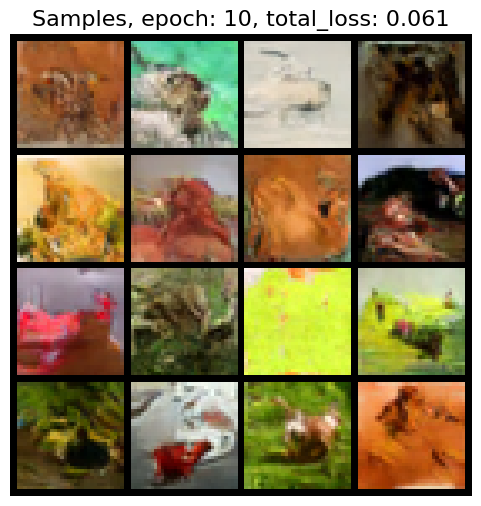

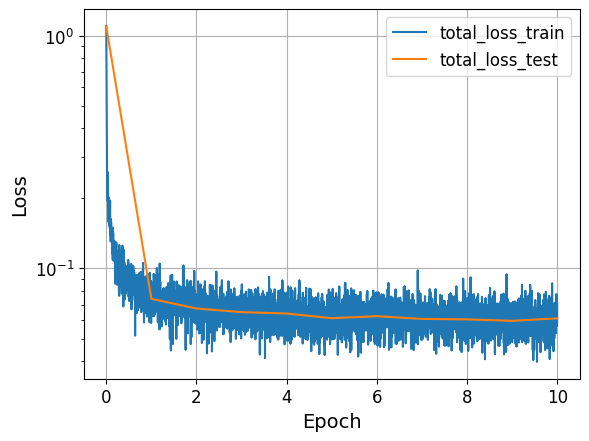

End of the training


In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
LR = 
EPOCHS = 
HIDDEN_CHANNELS = 
CHANNEL_MULTIPLIERS = 
NUM_BLOCKS = 
T = 
# ====

cond_model = UNet(
    num_timesteps=T, 
    num_labels=10, 
    hidden_channels=HIDDEN_CHANNELS, 
    channel_multipliers=CHANNEL_MULTIPLIERS, 
    num_blocks=NUM_BLOCKS
)
cond_ddpm = ConditionalDDPM(num_timesteps=T, model=cond_model)

# try your own optimizer/scheduler
optimizer = torch.optim.AdamW(cond_ddpm.parameters(), lr=LR, weight_decay=0.0001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.9)

# train unconditional mode
train_loader = data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
train_model(
    cond_ddpm,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    scheduler=scheduler,
    conditional=False,
    device=DEVICE,
    n_samples=16,
    visualize_samples=True, # prabably you would like to turn this off
    logscale_y=True,
)
# to save your time you can save the model
# torch.save(cond_ddpm.state_dict(), "unconditional_ddpm.pth")

Let's draw samples from the trained unconditional model.

In [ ]:
cond_ddpm.eval()
cond_ddpm = cond_ddpm.to(DEVICE)

num_samples = 100
y = None
samples = cond_ddpm.sample(num_samples=num_samples, y=y).cpu().numpy()
show_samples(samples, title="Samples")

Now lets fine-tune our unconditional model on samples with lables to make it **conditional**.

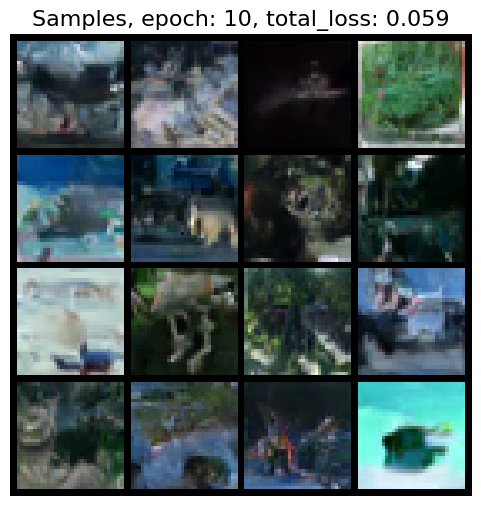

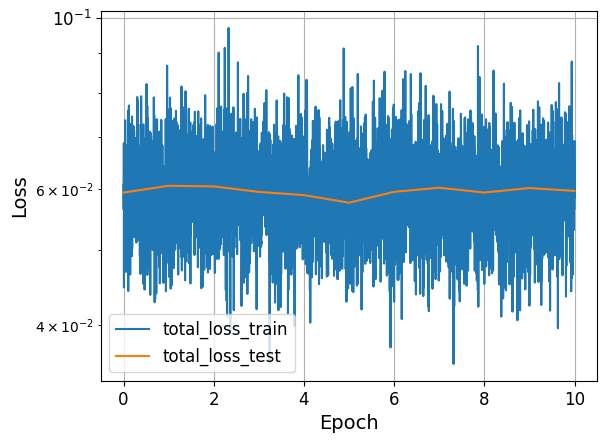

End of the training


In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
LR =
EPOCHS = 
HIDDEN_CHANNELS = 
CHANNEL_MULTIPLIERS = 
NUM_BLOCKS = 
T = 
# ====

# you can load the model with this code
# cond_model = UNet(
#     num_timesteps=T, 
#     num_labels=10, 
#     hidden_channels=HIDDEN_CHANNELS, 
#     channel_multipliers=CHANNEL_MULTIPLIERS, 
#     num_blocks=NUM_BLOCKS
# )
# cond_ddpm = ConditionalDDPM(num_timesteps=T, model=cond_model)
# cond_ddpm.load_state_dict(torch.load("unconditional_ddpm.pth"))

# optimizer = torch.optim.AdamW(cond_ddpm.parameters(), lr=LR, weight_decay=0.0001)
# scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.9)

# train conditional mode
train_loader = data.DataLoader(LabeledDataset(train_data, train_labels), batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(LabeledDataset(test_data, test_labels), batch_size=BATCH_SIZE, shuffle=False)
train_model(
    cond_ddpm,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    conditional=True,
    device=DEVICE,
    n_samples=16,
    visualize_samples=True,  # prabably you would like to turn this off
    logscale_y=True,
)

Let's draw samples with guidance.

In [ ]:
cond_ddpm.eval()
cond_ddpm = cond_ddpm.to(DEVICE)

num_samples = 100
y = (torch.arange(num_samples) % 10).to(DEVICE)
samples = cond_ddpm.sample(num_samples=num_samples, y=y).cpu().numpy()
show_samples(samples, title="Samples")

## Task 3: Diffusion Samplers (4 pts)

We will compare the strided DDPM sampler from Task 2 with Predictor-Corrector and DDIM on CIFAR10. We compute FID using samples generated without class labels.


### Fréchet Inception Distance

To evaluate sample quality, we use Fréchet Inception Distance (FID).

The idea is simple: we pass real and generated images through a pretrained feature extractor, get feature vectors, and approximate their distributions with Gaussians. Then FID measures the distance between these two Gaussian distributions.

If $(\mu_r, \Sigma_r)$ are mean and covariance of real features, and $(\mu_g, \Sigma_g)$ are mean and covariance of generated features, then
$$
    \mathrm{FID}
    =
    \|\mu_r - \mu_g\|_2^2
    +
    \operatorname{Tr}\left(
    \Sigma_r + \Sigma_g - 2(\Sigma_r \Sigma_g)^{1/2}
    \right).
$$

Smaller FID usually means that generated samples are closer to real ones in the feature space.

We provide the FID calculation using TorchMetrics. See the [FID documentation](https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance.html) for details.

In [20]:
@torch.no_grad()
def compute_fid(
    metric: FID,
    sampler,
    num_samples: int,
    batch_size: int,
    **sample_kwargs
) -> float:
    remaining = num_samples
    pbar = tqdm(total=num_samples, desc="Sampling")
    while remaining > 0:
        cur_bs = min(batch_size, remaining)

        samples = sampler.sample(
            num_samples=cur_bs,
            **sample_kwargs
        )
        metric.update(samples, real=False)
        remaining -= cur_bs
        pbar.update(cur_bs)

    fid_value = metric.compute().item()
    return fid_value

Let's compute the real-image feature statistics once and reuse them for all three samplers.

In [21]:
BATCH_SIZE = 128

fid = FID(feature=2048, normalize=True, reset_real_features=False).to(DEVICE)

test_loader = data.DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
for batch in tqdm(test_loader):
    batch = batch.to(DEVICE)
    fid.update(batch, real=True)


  0%|          | 0/79 [00:00<?, ?it/s]

First, let us measure FID for the strided DDPM sampler from Task 2.

**Note:** choose `NUM_TIMESTEPS` between 1 and `cond_ddpm.num_timesteps`.


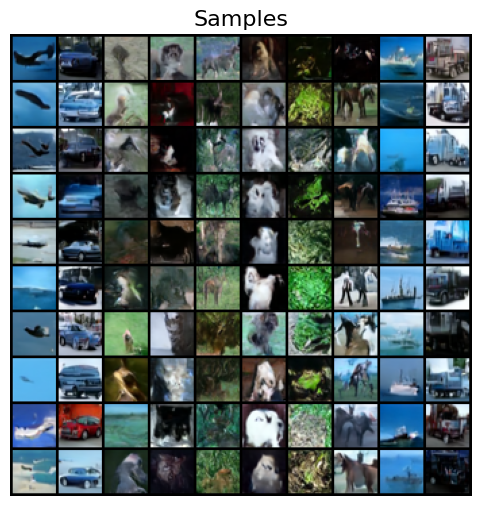

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
NUM_TIMESTEPS = 
# ====

sampler = cond_ddpm.eval()

num_samples = 100
y = (torch.arange(num_samples) % 10).to(DEVICE)
samples = sampler.sample(
    num_samples=num_samples, y=y, num_timesteps=NUM_TIMESTEPS
).cpu().numpy()
show_samples(samples, title="Samples")

In [23]:
fid.reset()
fid_value = compute_fid(
    fid,
    sampler,
    num_samples=len(test_data),
    batch_size=BATCH_SIZE,
    num_timesteps=NUM_TIMESTEPS,
)
print(f"FID: {fid_value:.4f}")

Sampling:   0%|          | 0/10000 [00:00<?, ?it/s]

FID: 75.4323


### Problem 1: Predictor-Corrector Sampler (2 pts)

Let us extend `ConditionalDDPM` with **correction** steps by overriding `sample`.

Recall from NCSN and Langevin dynamics that, if we know the score function $\nabla_{\mathbf{x}} \log p(\mathbf{x})$, we can refine samples by moving them towards regions of higher density and adding a small amount of noise.

The idea of Predictor-Corrector uses this knowledge:
- **Predictor** makes the usual reverse diffusion step from $\mathbf{x}_t$ to an earlier timestep.
- **Corrector** additionally refines the current sample at the same timestep $t$ before this transition.

To do this, we recover the score from the predicted noise $\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y})$. From the forward diffusion formula, at timestep $t$ we have
$$
    \nabla_{\mathbf{x}_t} \log q(\mathbf{x}_t)
    \approx
    -\frac{\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y})}{\sqrt{1-\bar{\alpha}_t}}.
$$

Then we apply a Langevin correction step using the Euler-Maruyama discretization:
$$
    \mathbf{x}_t
    \leftarrow
    \mathbf{x}_t + \eta_t \, \mathbf{s}_t + \sqrt{2\eta_t}\,\mathbf{z},
    \qquad
    \mathbf{s}_t
    =
    -\frac{\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y})}{\sqrt{1-\bar{\alpha}_t}},
    \qquad
    \mathbf{z}\sim\mathcal{N}(0,\mathbf{I}).
$$

In our implementation, the step size is chosen adaptively from the target signal-to-noise ratio:
$$
    \eta_t
    =
    2\left(
    \frac{\mathrm{target\_snr}\cdot \|\mathbf{z}\|_2}
    {\|\mathbf{s}_t\|_2}
    \right)^2,
$$
where in practice we use batch-average norms of the noise and the score.

After one or more correction steps at timestep $t$, we take the strided DDPM step from Task 2.

In [ ]:
class PredictorCorrectorSampler(ConditionalDDPM):
    @torch.no_grad()
    def sample(
        self,
        num_samples: int,
        y: Optional[torch.Tensor] = None,
        guidance_scale: float = 3.0,
        num_timesteps: Optional[int] = None,
        corrector_steps: int = 1,
        target_snr: float = 0.16,
    ):
        assert self.shape is not None
        x = torch.randn((num_samples, *self.shape), device=self.device, dtype=torch.float32)

        for i, idx in self.get_sampling_steps(num_timesteps):
            t = torch.full((num_samples,), i, device=x.device, dtype=torch.long)
            s = torch.full((num_samples,), idx, device=x.device, dtype=torch.long)

            alpha_bar_t = extract_into_tensor(
                self.reverse_diffusion.alphas_cumprod, t, x.shape
            )
            for _ in range(corrector_steps):
                # ====
                # your code
                # 1) get epsilon from the model without conditioning
                # 2) if y is not None then 
                #    get epsilon from the model with conditioning
                #    modify epsilon with classifier-free guidance formula
                # 3) convert it to the score estimate
                # 4) choose the Langevin step size from the target SNR
                # 5) update x with one Langevine step
                
                # ====
            
            # ====
            # your code
            # 1) get epsilon from the model without conditioning
            # 2) if y is not None then 
            #    get epsilon from the model with conditioning
            #    modify epsilon with classifier-free guidance formula
            # 3) sample from the reverse diffusion
            
            # ====

        return torch.clamp(0.5 * x + 0.5, 0.0, 1.0)

Let us generate samples with the same DDPM and add correction steps.

**Note:** before computing FID, it is recommended to first inspect the generated samples visually and choose the best parameters for sampling.

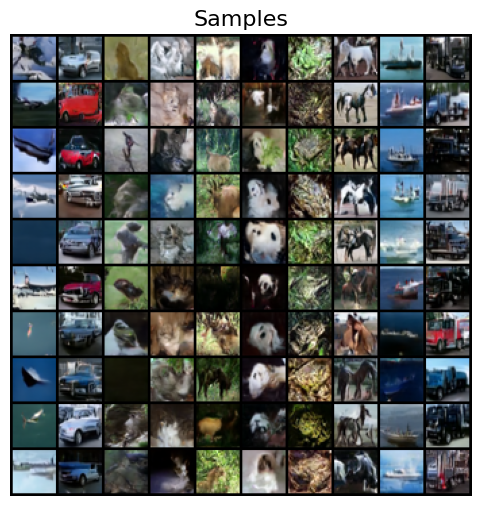

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
NUM_TIMESTEPS = 
CORRECTOR_STEPS = 
TARGET_SNR = 
# ====

model = cond_ddpm.model

sampler = PredictorCorrectorSampler(
    model=model,
    num_timesteps=cond_ddpm.num_timesteps,
    shape=cond_ddpm.shape,
).to(DEVICE).eval()

num_samples = 100
y = (torch.arange(num_samples) % 10).to(DEVICE)
samples = sampler.sample(
    num_samples=num_samples, y=y,
    num_timesteps=NUM_TIMESTEPS, 
    corrector_steps=CORRECTOR_STEPS,
    target_snr=TARGET_SNR,
).cpu().numpy()
show_samples(samples, title="Samples")

In [26]:
fid.reset()
fid_value = compute_fid(
    fid,
    sampler,
    num_samples=len(test_data),
    batch_size=BATCH_SIZE,
    num_timesteps=NUM_TIMESTEPS,
    corrector_steps=CORRECTOR_STEPS,
    target_snr=TARGET_SNR,
)
print(f"FID: {fid_value:.4f}")

Sampling:   0%|          | 0/10000 [00:00<?, ?it/s]

FID: 70.6380


### Problem 2: DDIM Sampler (2 pts)

Now let us implement the **DDIM sampler** by overriding `ConditionalDDPM.sample`.

DDIM uses a **deterministic** update between timesteps. As before, at timestep $t$ we first predict the noise $\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y})$ and recover
$$
    \hat{\mathbf{x}}_0
    =
    \frac{\mathbf{x}_t-\sqrt{1-\bar{\alpha}_t}\,\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y})}{\sqrt{\bar{\alpha}_t}}.
$$

Then, instead of sampling from a Gaussian transition, we directly move to an earlier timestep $s < t$ using
$$
    \mathbf{x}_s
    =
    \sqrt{\bar{\alpha}_s}\,\hat{\mathbf{x}}_0
    +
    \sqrt{1-\bar{\alpha}_s}\,\boldsymbol{\epsilon}_{\theta,t}(\mathbf{x}_t, \mathbf{y}).
$$

Such a construction defines a non-Markovian reverse process whose marginals are **consistent with the original forward diffusion process**. So DDIM keeps the same marginals as in DDPM, but uses a deterministic trajectory for sampling.


In [ ]:
class DDIMSampler(ConditionalDDPM):
    @torch.no_grad()
    def sample(
        self,
        num_samples: int,
        y: Optional[torch.Tensor] = None,
        guidance_scale: float = 3.0,
        num_timesteps: Optional[int] = None,
    ):
        assert self.shape is not None
        x = torch.randn((num_samples, *self.shape), device=self.device, dtype=torch.float32)

        for i, idx in self.get_sampling_steps(num_timesteps):
            t = torch.full((num_samples,), i, device=x.device, dtype=torch.long)
            s = torch.full((num_samples,), idx, device=x.device, dtype=torch.long)

            if idx >= 0:
                alpha_bar_s = extract_into_tensor(
                    self.reverse_diffusion.alphas_cumprod, s, x.shape
                )

            # ====
            # your code
            # 1) get epsilon from the model without conditioning
            # 2) if y is not None then 
            #    get epsilon from the model with conditioning
            #    modify epsilon with classifier-free guidance formula
            # 3) get x0 from the reverse diffusion
            # 4) update x with the determenistic DDIM formula
            
            # ====

        return torch.clamp(0.5 * x + 0.5, 0.0, 1.0)

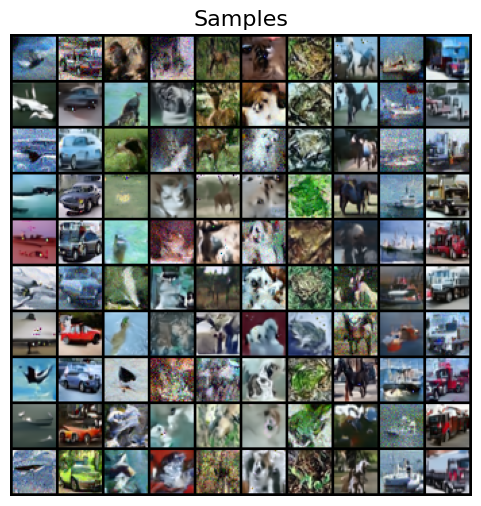

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
NUM_TIMESTEPS = 
# ====

model = cond_ddpm.model

sampler = DDIMSampler(
    model=model,
    num_timesteps=cond_ddpm.num_timesteps,
    shape=cond_ddpm.shape,
).to(DEVICE).eval()

num_samples = 100
y = (torch.arange(num_samples) % 10).to(DEVICE)
samples = sampler.sample(
    num_samples=num_samples, y=y,
    num_timesteps=NUM_TIMESTEPS, 
).cpu().numpy()
show_samples(samples, title="Samples")

In [29]:
fid.reset()
fid_value = compute_fid(
    fid,
    sampler,
    num_samples=len(test_data),
    batch_size=BATCH_SIZE,
    num_timesteps=NUM_TIMESTEPS,
)
print(f"FID: {fid_value:.4f}")

Sampling:   0%|          | 0/10000 [00:00<?, ?it/s]

FID: 72.4969
